# Seeded track: figures

Makes every figure for the seeded track and the numbers behind them:

| File in `results/seeded/` | Shows |
|---|---|
| `novel_passes_vs_sims.png` | new (novel) passing designs vs. simulations, screened (ML) vs. random picks |
| `score_gain_vs_sims.png` | hypervolume added vs. simulations, same arms |
| `hypervolume_expansion.png` | hypervolume of the public NFP-3 4×4 designs, what ours add, and the utopia point |
| `arm_comparison.json` | all numbers above |

**Scope: NFP 3, 4×4 Fourier modes** (80 shape coefficients), the resolution of the dataset and of the paper's baseline. "Public front" here means the front of the public passing designs in that space (HV 205.5). The leaderboard's best front is higher resolution (NFP 3 and 4, 8×8 and 9×9 modes; HV 285.3, computed below), and our designs add nothing to it. The novel-pass comparison between arms doesn't involve any front; the score-gain curves are measured against the 4×4 one.

**Arms:** `b60_random_s{10,11,12}` and `b60_screen_s{10,11,12}` from `scripts/seeded/loop.py` (5 rounds of 60, blend proposer). Gains are measured from the shared start every arm saw (pilot + surface batch).

**Needs** the local simulation results in `data/seeded/` (gitignored), i.e. run the arms first. Kernel: the `stellarator` env.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch, Rectangle

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "seeded").is_dir())
sys.path[:0] = [str(ROOT / "scripts" / "seeded"), str(ROOT / "scripts")]
import loop
import training_data
from families import NOVELTY, STRICT, load, nearest_public
from perturb import front_mask
from screen import TOL, load_table

LOGS, OUT = ROOT / "data" / "seeded" / "logs", ROOT / "results" / "seeded"
OUT.mkdir(parents=True, exist_ok=True)
SEEDS = (10, 11, 12)
REF_A, REF_L = loop.REF_A, loop.REF_L

INK, INK2, MUTED, RULE = "#111620", "#465063", "#6f7a8c", "#dce1e9"
BLUE, BLUE_FILL, ORANGE = "#2a78d6", "#9ec5f4", "#eb6834"
ARMS = {"random": dict(color=MUTED, marker="s", label="Random picks (no ML)"),
        "screen": dict(color=ORANGE, marker="o", label="Screened picks (ML)")}
plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 10.5, "axes.labelsize": 9, "axes.labelcolor": INK2,
    "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": MUTED, "axes.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": RULE, "grid.linewidth": 0.6, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": "white",
})

## Data

Rebuild the training table from every simulation ledger, then find our novel passing designs (≥ 0.003 RMS surface distance from every public design).

In [2]:
training_data.build()
t = load_table()
pub = load()
hv_pub = loop.hypervolume(pub["A"], pub["L"])


def novel_passes(t, thresh=NOVELTY):
    ok = (t["source"] == "ours") & ~t["crash"] & (t["max_violation"] <= TOL)
    m = np.zeros(len(t["X"]), bool)
    if ok.any():
        m[ok] = nearest_public(t["X"][ok]) >= thresh
    return m


# the shared start: what every arm saw before its own simulations
shared = loop.arm_view(t, "__shared_only__")
ms = novel_passes(shared)
base_n = int(ms.sum())
base_pp = loop.hypervolume(np.r_[pub["A"], shared["A"][ms]], np.r_[pub["L"], shared["L"][ms]])

curves = {}
for kind in ARMS:
    curves[kind] = []
    for s in SEEDS:
        rows = [json.loads(x) for x in (LOGS / f"loop_b60_{kind}_s{s}.jsonl").open()]
        curves[kind].append({
            "seed": s,
            "sims": [0, *np.cumsum([r["simulated"] for r in rows]).tolist()],
            "novel": [0, *[r["novel_passing_total"] - base_n for r in rows]],
            "gain": [0.0, *[r["hv_public_plus_ours"] - base_pp for r in rows]],
            "pass_rate": [r["passed"] / r["simulated"] for r in rows]})

pooled = {}
for thresh, name in ((NOVELTY, "novelty_0.003"), (STRICT, "novelty_0.01")):
    m = novel_passes(t, thresh)
    pooled[name] = {"novel_passes": int(m.sum()),
                    "hv_ours_alone": loop.hypervolume(t["A"][m], t["L"][m]),
                    "hv_public_plus_ours": loop.hypervolume(np.r_[pub["A"], t["A"][m]],
                                                            np.r_[pub["L"], t["L"][m]])}
m = novel_passes(t)
print(f"public NFP-3 4x4 front HV {hv_pub:.3f}; shared start: {base_n} novel passes, public+ours {base_pp:.3f}")
for name, p in pooled.items():
    print(f"pooled ({name}): {p['novel_passes']} novel passes, ours alone {p['hv_ours_alone']:.3f}, "
          f"public+ours {p['hv_public_plus_ours']:.3f}")

/Users/joelpederson/Documents/School/Cambridge/Fall 2026/2.156 AIML for Engineering Design/final-project/scripts/seeded/training_data.py:113: RuntimeWarning: All-NaN slice encountered
  "dataset": dict(ds, max_violation=np.nanmax(np.maximum(ds["violations"], 0), axis=1)
/Users/joelpederson/Documents/School/Cambridge/Fall 2026/2.156 AIML for Engineering Design/final-project/scripts/seeded/training_data.py:115: RuntimeWarning: All-NaN slice encountered
  "ours": dict(ours, max_violation=np.nanmax(np.maximum(ours["violations"], 0), axis=1)


  dataset :  82043 designs, 13852 crashed,     0 pass
  ours    :   3947 designs,    75 crashed,  1469 pass
  public  :   8074 designs,     0 crashed,  8074 pass


public NFP-3 4x4 front HV 205.518; shared start: 67 novel passes, public+ours 207.755
pooled (novelty_0.003): 1061 novel passes, ours alone 206.413, public+ours 208.683
pooled (novelty_0.01): 389 novel passes, ours alone 197.264, public+ours 207.355


## Screened vs. random picks

Three runs per method; line = mean, band = range over runs. Labels sit up-left (screened) or down-right (random) of a chosen point so they stay off both lines.

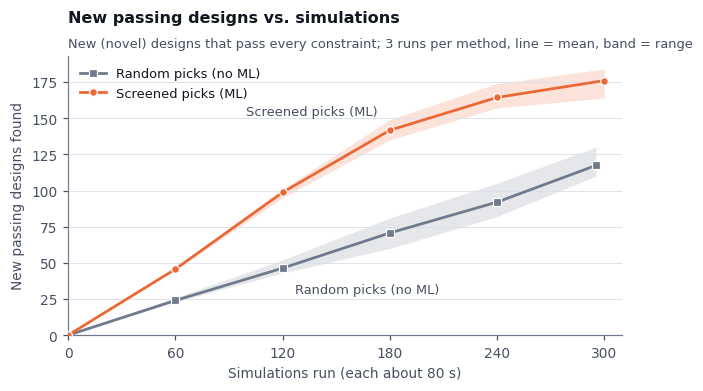

In [3]:
def curve_figure(key, title, subtitle, ylabel, labels, path):
    fig, ax = plt.subplots(figsize=(6.5, 3.3))
    for kind, st in ARMS.items():
        x = np.mean([r["sims"] for r in curves[kind]], axis=0)
        y = np.array([r[key] for r in curves[kind]], float)
        ax.fill_between(x, y.min(0), y.max(0), color=st["color"], alpha=0.18, lw=0)
        ax.plot(x, y.mean(0), color=st["color"], lw=1.8, marker=st["marker"], ms=5,
                mec="white", mew=0.8, label=st["label"], zorder=3)
        i, dx, dy = labels[kind]
        ax.annotate(st["label"], (x[i], y.mean(0)[i]), xytext=(dx, dy), textcoords="offset points",
                    ha="right" if dx < 0 else "left", va="bottom" if dy > 0 else "top",
                    color=INK2, fontsize=8.5)
    ax.set_xlim(0, 310)
    ax.set_ylim(bottom=0)
    ax.set_xticks(range(0, 301, 60))
    ax.set_xlabel("Simulations run (each about 80 s)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", pad=22, fontweight="semibold")
    ax.text(0, 1.03, subtitle, transform=ax.transAxes, color=INK2, fontsize=8.5)
    ax.legend(loc="upper left", fontsize=8.5)
    fig.savefig(path)
    plt.show()


curve_figure("novel", "New passing designs vs. simulations",
             "New (novel) designs that pass every constraint; 3 runs per method, line = mean, band = range",
             "New passing designs found", {"screen": (3, -8, 8), "random": (2, 8, -10)},
             OUT / "novel_passes_vs_sims.png")

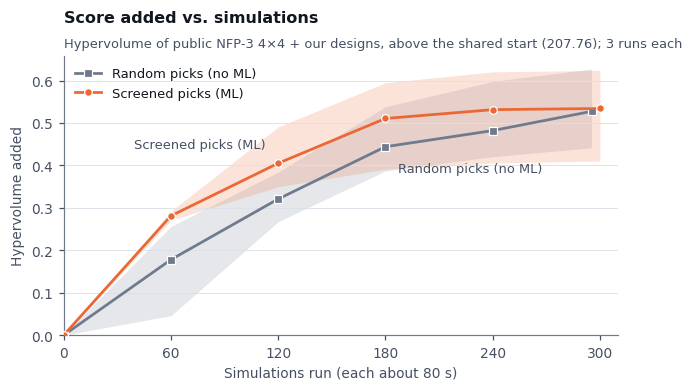

In [4]:
curve_figure("gain", "Score added vs. simulations",
             f"Hypervolume of public NFP-3 4×4 + our designs, above the shared start ({base_pp:.2f}); 3 runs each",
             "Hypervolume added", {"screen": (2, -8, 8), "random": (3, 8, -10)},
             OUT / "score_gain_vs_sims.png")

## Hypervolume in the NFP-3 4×4 design space

Blue: the region the public NFP-3 4×4 designs dominate, measured from the reference point (A = 20, L∇B = −1). Orange, drawn underneath: the extra region once our novel designs are added. The **utopia point** combines the best A and the best L∇B found on the combined front; the dotted box from the reference point to it is the most score any front could reach with those extremes.

The leaderboard's full front (all resolutions, HV 285.3) is far above this one and isn't drawn; the cell prints both numbers.

full public front (all 19898 passing designs, any NFP/resolution): HV 285.271; with ours 285.271 (gain +0.000)


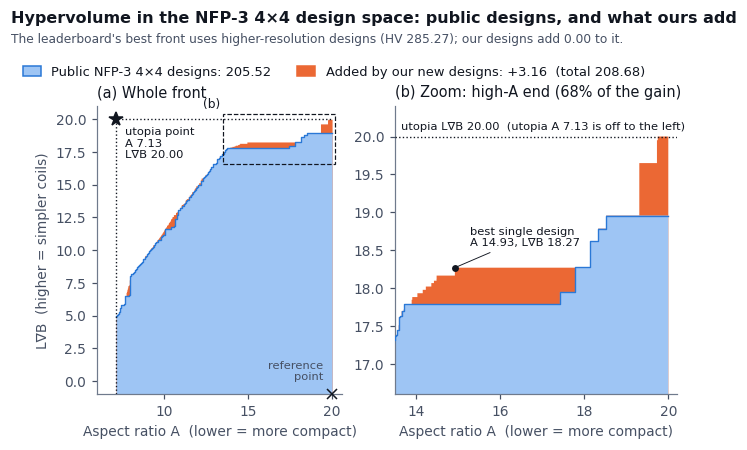

utopia box HV 270.3: public 4x4 front covers 76.0%, with ours 77.2%


In [5]:
def steps(A, L):
    """The front as a staircase down/right to the reference point."""
    k = front_mask(A, L)
    o = np.argsort(A[k])
    a, l = A[k][o], L[k][o]
    return np.r_[a, REF_A], np.r_[l, l[-1]]


A, L = t["A"][m], t["L"][m]
g = loop.hv_gain(A, L, pub["A"], pub["L"])
full = [json.loads(x) for x in (ROOT / "data" / "seeded" / "public_p3.jsonl").open()]
fA = np.array([r["aspect_ratio"] for r in full if r["feasible"]])
fL = np.array([r["L_gradB"] for r in full if r["feasible"]])
hv_full, hv_full_plus = loop.hypervolume(fA, fL), loop.hypervolume(np.r_[fA, A], np.r_[fL, L])
print(f"full public front (all {len(fA)} passing designs, any NFP/resolution): HV {hv_full:.3f}; "
      f"with ours {hv_full_plus:.3f} (gain {hv_full_plus - hv_full:+.3f})")
best = (float(A[np.argmax(g)]), float(L[np.argmax(g)]))
hv_all = pooled["novelty_0.003"]["hv_public_plus_ours"]
xp, yp = steps(pub["A"], pub["L"])
xu, yu = steps(np.r_[pub["A"], A], np.r_[pub["L"], L])
ua, ul = float(xu[0]), float(yu.max())                 # utopia point
zoom = (13.5, 20.2, 16.6, 20.4)

grid = np.linspace(xu[0], REF_A, 200001)
def height(xs, ys):
    i = np.searchsorted(xs, grid, side="right") - 1
    return np.where(i >= 0, ys[np.clip(i, 0, None)], REF_L)
added = height(xu, yu) - height(xp, yp)
share = added[grid >= zoom[0]].sum() / added.sum()

fig, axes = plt.subplots(1, 2, figsize=(6.8, 3.4), gridspec_kw={"width_ratios": [1, 1.15]})
for ax in axes:
    ax.fill_between(xu, REF_L, yu, step="post", color=ORANGE, lw=0, zorder=1)
    ax.fill_between(xp, REF_L, yp, step="post", color=BLUE_FILL, lw=0, zorder=2)
    ax.step(xp, yp, where="post", color=BLUE, lw=0.9, zorder=3)
    ax.grid(False)
    ax.set_xlabel("Aspect ratio A  (lower = more compact)")
a, b = axes
a.set_xlim(6, 20.6)
a.set_ylim(REF_L, 21)
a.set_ylabel("L∇B  (higher = simpler coils)")
a.plot([REF_A], [REF_L], marker="x", color=INK, ms=6, clip_on=False, zorder=4)
a.annotate("reference\npoint", (REF_A, REF_L), xytext=(-6, 8), textcoords="offset points",
           ha="right", va="bottom", fontsize=7.5, color=INK2)
a.plot([ua, ua, REF_A], [REF_L, ul, ul], ls=":", color=INK, lw=0.9, zorder=4)
a.plot([ua], [ul], marker="*", color=INK, ms=9, zorder=6, clip_on=False)
a.annotate(f"utopia point\nA {ua:.2f}\nL∇B {ul:.2f}", (ua, ul), xytext=(6, -5),
           textcoords="offset points", ha="left", va="top", fontsize=7.5, color=INK)
x0, x1, y0, y1 = zoom
a.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=INK, lw=0.8, ls="--", zorder=5))
a.annotate("(b)", (x0, y1), xytext=(-2, 2), textcoords="offset points", ha="right", va="bottom",
           fontsize=8, color=INK)
a.set_title("(a) Whole front", loc="left", fontsize=9.5)
b.set_xlim(x0, x1)
b.set_ylim(y0, y1)
b.set_title(f"(b) Zoom: high-A end ({share:.0%} of the gain)", loc="left", fontsize=9.5)
b.axhline(ul, ls=":", color=INK, lw=0.9, zorder=4)
b.annotate(f"utopia L∇B {ul:.2f}  (utopia A {ua:.2f} is off to the left)", (x0, ul), xytext=(4, 3),
           textcoords="offset points", ha="left", va="bottom", fontsize=7.5, color=INK)
b.plot([best[0]], [best[1]], "o", color=INK, ms=3.5, zorder=4)
b.annotate(f"best single design\nA {best[0]:.2f}, L∇B {best[1]:.2f}", best, xytext=(10, 14),
           textcoords="offset points", fontsize=7.5, color=INK,
           arrowprops=dict(arrowstyle="-", color=INK, lw=0.6))
fig.suptitle("Hypervolume in the NFP-3 4×4 design space: public designs, and what ours add",
             x=0.01, ha="left", va="top", fontsize=10.5, fontweight="semibold", y=1.135)
fig.text(0.01, 1.075, f"The leaderboard's best front uses higher-resolution designs (HV {hv_full:.2f}); "
         f"our designs add {hv_full_plus - hv_full:.2f} to it.", ha="left", va="top", fontsize=8, color=INK2)
fig.legend(handles=[Patch(color=BLUE_FILL, ec=BLUE, label=f"Public NFP-3 4×4 designs: {hv_pub:.2f}"),
                    Patch(color=ORANGE, label=f"Added by our new designs: +{hv_all - hv_pub:.2f}  (total {hv_all:.2f})")],
           loc="upper left", bbox_to_anchor=(0.01, 1.02), ncol=2, fontsize=8.5, handlelength=1.4)
fig.savefig(OUT / "hypervolume_expansion.png")
plt.show()

box = (REF_A - ua) * (ul - REF_L)
utopia = {"A": ua, "L_gradB": ul, "box_hv": box,
          "public_share_of_box": hv_pub / box, "combined_share_of_box": hv_all / box}
print(f"utopia box HV {box:.1f}: public 4x4 front covers {hv_pub / box:.1%}, with ours {hv_all / box:.1%}")

## Numbers

In [6]:
summary = {"scope": "NFP 3, 4x4 Fourier modes",
           "public_front": "public passing NFP-3 4x4 designs", "public_front_hv": hv_pub,
           "full_public_front_hv": hv_full, "full_public_front_hv_with_ours": hv_full_plus,
           "utopia": utopia,
           "simulations_total": int((t["source"] == "ours").sum()),
           "shared_start": {"novel_passes": base_n, "hv_public_plus_ours": base_pp},
           "arms": curves, "pooled": pooled,
           "best_single_design": {"id": str(t["id"][m][np.argmax(g)]), "A": best[0],
                                  "L_gradB": best[1], "hv_gain_alone": float(g.max())}}
(OUT / "arm_comparison.json").write_text(json.dumps(summary, indent=1))

print(f"{'simulations':>11} | {'novel passes: random':>21} {'screened':>9} | {'HV added: random':>17} {'screened':>9}")
for i, n in enumerate(curves["screen"][0]["sims"]):
    r = [np.mean([c[k][i] for c in curves["random"]]) for k in ("novel", "gain")]
    s = [np.mean([c[k][i] for c in curves["screen"]]) for k in ("novel", "gain")]
    print(f"{n:11d} | {r[0]:21.1f} {s[0]:9.1f} | {r[1]:17.3f} {s[1]:9.3f}")

simulations |  novel passes: random  screened |  HV added: random  screened
          0 |                   0.0       0.0 |             0.000     0.000
         60 |                  24.0      45.7 |             0.178     0.281
        120 |                  46.3      98.7 |             0.321     0.405
        180 |                  70.7     141.7 |             0.444     0.511
        240 |                  92.0     164.3 |             0.482     0.531
        300 |                 117.3     176.0 |             0.527     0.534
